# Reconnaissance de Variétés de Haricots Secs (UCI Dry Bean Dataset)
### Projet 02 — Machine Learning | INSEA 2026–2027
**Auteurs :**  Youssef *FATIMI*, Hamza *BALLA*, Mohamed Yahya *SAFADI*, Ayoub *ELHANAFI*


---

##  Protocole Expérimental Commun (Standard de l'Équipe)

Pour garantir une comparabilité scientifique absolue et prévenir toute divergence méthodologique :
1. **Graine Aléatoire Universelle :** `random_state = 42` fixée à tous les niveaux (découpage, validation croisée, initialisation des estimateurs).
2. **Séparation Étanche :** 80% Entraînement (10 888 graines) / 20% Test (2 723 graines) avec stratification stricte sur la variable cible `Class`.
3. **Prévention de la Fuite d'Information (*Zero Data Leakage*) :** Le `StandardScaler` est systématiquement encapsulé dans un `Pipeline` Scikit-Learn. Les paramètres $(\mu, \sigma)$ sont appris exclusivement sur les plis d'entraînement lors de la CV, puis appliqués sans réajustement sur le jeu de test.
4. **Validation Croisée Stratifiée (Train uniquement) :** `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` pour toutes les recherches d'hyperparamètres (`GridSearchCV`).
5. **Métrique d'Arbitrage Reine :** **F1-Score Macro**, indispensable compte tenu du déséquilibre des 7 classes (de 3.8% pour *Bombay* à 26.1% pour *Dermason*).
6. **Évaluation Finale Unique :** Les estimateurs optimaux ne sont évalués qu'une seule fois sur le jeu de test conservé intact jusqu'à la phase d'arbitrage.

In [18]:
import os
import time
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, learning_curve
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier

# Algorithmes étudiés
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC, LinearSVC

# Métriques d'évaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

SEED = 42
np.random.seed(SEED)

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs("rapport_latex/figures", exist_ok=True)
os.makedirs("presentation_beamer/figures", exist_ok=True)

def save_fig(fig, filename):
    """Sauvegarde une figure en haute résolution dans les dossiers partagés."""
    path_main = os.path.join(FIG_DIR, filename)
    fig.savefig(path_main, dpi=300, bbox_inches="tight")
    for target_dir in ["rapport_latex/figures", "presentation_beamer/figures"]:
        target_path = os.path.join(target_dir, filename)
        shutil.copy2(path_main, target_path)
    print(f"Figure sauvegardée : {path_main} (300 DPI)")

print("Environnement configuré avec succès | Graine universelle :", SEED)

Environnement configuré avec succès | Graine universelle : 42


## 1. Chargement & Exploration des Données (EDA Unifiée)
Le jeu de données officiel *UCI Dry Bean Dataset* contient 13 611 observations et 16 descripteurs géométriques et morphologiques continus décrivant 7 variétés de haricots secs.

In [19]:
df = pd.read_csv("Dry_Bean_Dataset.csv")
df.columns = [c.lstrip("\ufeff").strip() for c in df.columns]

X = df.drop(columns="Class")
y = df["Class"]
classes = sorted(y.unique())

print(f"Dimensions globales : {df.shape[0]} observations, {df.shape[1]} colonnes")
print(f"Nombre total de valeurs manquantes : {df.isna().sum().sum()}")
print(f"Nombre de lignes dupliquées : {df.duplicated().sum()}")
print("Classes cibles (7 variétés) :", classes)

Dimensions globales : 13611 observations, 17 colonnes
Nombre total de valeurs manquantes : 0
Nombre de lignes dupliquées : 68
Classes cibles (7 variétés) : ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


,Effectif,Proportion (%)
Class,,
BARBUNYA,1322,9.71
BOMBAY,522,3.84
CALI,1630,11.98
DERMASON,3546,26.05
HOROZ,1928,14.17
SEKER,2027,14.89
SIRA,2636,19.37


Figure sauvegardée : figures\01_eda_classes_distribution.png (300 DPI)


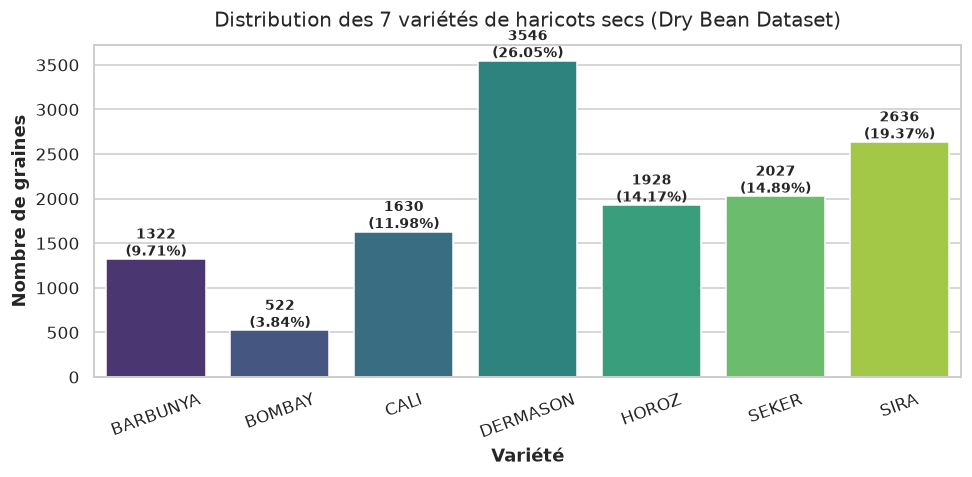

In [20]:
# Tableau récapitulatif des effectifs et proportions
counts = y.value_counts()[classes]
proportions = (y.value_counts(normalize=True)[classes] * 100).round(2)
df_classes = pd.DataFrame({"Effectif": counts, "Proportion (%)": proportions})
display(df_classes)

# Visualisation des effectifs par variété
fig, ax = plt.subplots(figsize=(9, 4.5))
palette = sns.color_palette("viridis", len(classes))
sns.barplot(x=counts.index, y=counts.values, palette=palette, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v + 40, f"{v}\n({proportions.iloc[i]}%)", ha="center", fontsize=9, fontweight="bold")
ax.set_title("Distribution des 7 variétés de haricots secs (Dry Bean Dataset)", fontsize=13, pad=12)
ax.set_xlabel("Variété", fontweight="bold")
ax.set_ylabel("Nombre de graines", fontweight="bold")
plt.xticks(rotation=20)
plt.tight_layout()
save_fig(fig, "01_eda_classes_distribution.png")
plt.show()

**Interprétation — Distribution des Classes :**
- **Déséquilibre marqué :** La variété `DERMASON` est la plus abondante avec 3 546 grains (26.05 %), tandis que `BOMBAY` est la plus rare avec seulement 522 grains (3.84 %), soit un ratio de 1 à 6.8.
- **Justification du F1-Score Macro :** L'accuracy globale est une métrique trompeuse face à une telle asymétrie (un classifieur prédisant uniquement les classes majoritaires afficherait un score artificiellement flatteur tout en ignorant les classes rares). Le **F1-score Macro** calcule la moyenne non pondérée des F1-scores de chaque classe, conférant un poids égal à chaque variété.
- **Nécessité de la stratification :** Le découpage et la validation croisée doivent impérativement être stratifiés (`stratify=y`) afin de garantir que les 3.84 % de `BOMBAY` sont fidèlement répliqués dans les ensembles d'entraînement et de test.

Figure sauvegardée : figures\02_eda_morphological_boxplots.png (300 DPI)


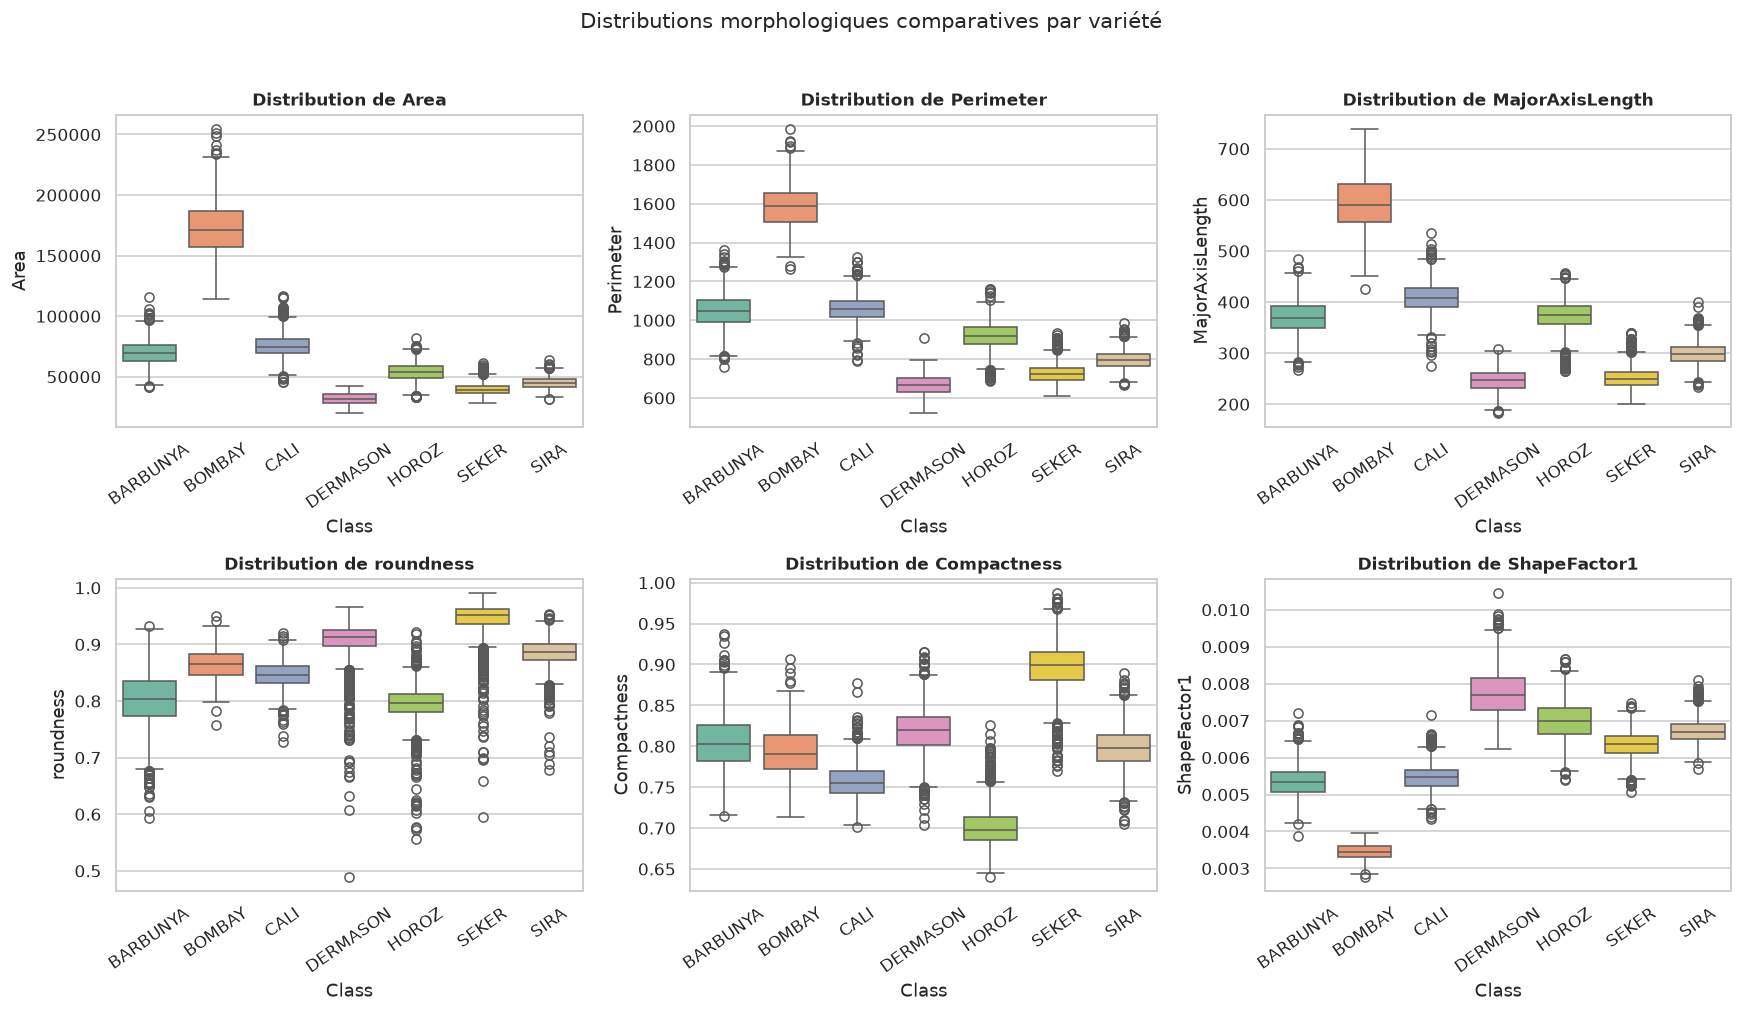

In [21]:
# Distributions de caractéristiques morphologiques clés
key_feats = ["Area", "Perimeter", "MajorAxisLength", "roundness", "Compactness", "ShapeFactor1"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feat in zip(axes.ravel(), key_feats):
    sns.boxplot(data=df, x="Class", y=feat, order=classes, palette="Set2", ax=ax)
    ax.set_title(f"Distribution de {feat}", fontweight="bold", fontsize=11)
    ax.tick_params(axis="x", rotation=35)
plt.suptitle("Distributions morphologiques comparatives par variété", fontsize=14, y=1.02)
plt.tight_layout()
save_fig(fig, "02_eda_morphological_boxplots.png")
plt.show()

**Interprétation — Distributions Morphologiques Comparatives :**
- **Isolement physique spectaculaire de BOMBAY :** Sa surface médiane (`Area` $\approx 173\,000$ px²) et son périmètre (`Perimeter` $\approx 1\,585$ px) sont plus de trois fois supérieurs à ceux de toutes les autres variétés (30 000 à 70 000 px²). Il s'agit d'une variété géante, quasi linéairement séparable par ses dimensions brutes.
- **Forme allongée et cylindrique de HOROZ :** Présente le grand axe (`MajorAxisLength`) le plus élevé après Bombay et un ratio d'aspect (`AspectRation`) dominant, couplé à une faible compacité.
- **Sphéricité quasi parfaite de SEKER :** Caractérisée par une circularité (`roundness` $\approx 0.94$) et une compacité (`Compactness` $\approx 0.91$) très élevées et resserrées, traduisant des grains quasi sphériques.
- **Le piège morphologique DERMASON / SIRA :** Leurs boîtes à moustaches sont presque confondues sur l'ensemble des 6 variables (aires, périmètres et facteurs de forme quasiment identiques). Ce chevauchement constitue la source majeure de confusion géométrique.
- **Disparité d'échelles :** Les variables dimensionnelles ($10^4 - 10^5$) coexistent avec des ratios adimensionnels ($10^{-3} - 1$), rendant la standardisation incontournable pour les algorithmes sensibles aux distances.

Figure sauvegardée : figures\03_correlation_matrix.png (300 DPI)


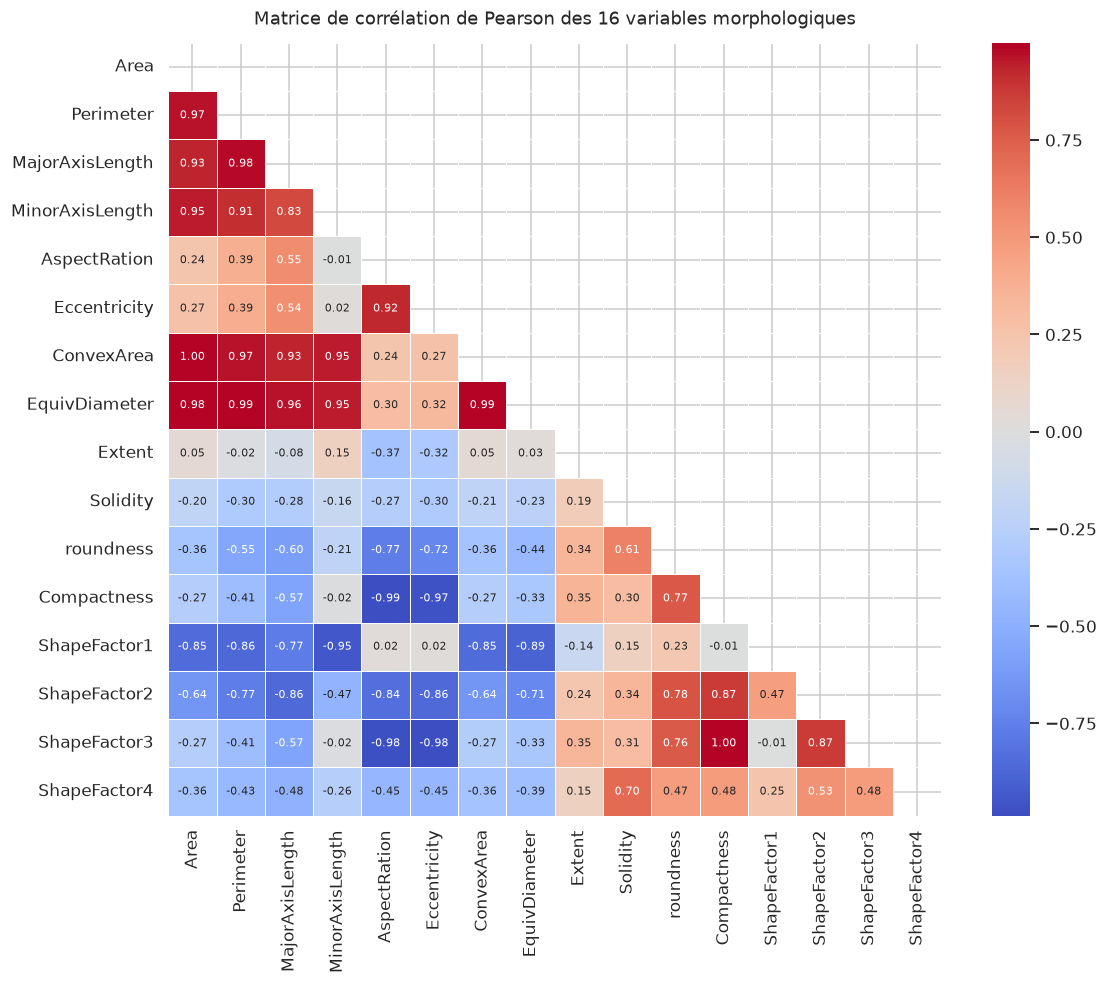

In [22]:
# Matrice de corrélation linéaire de Pearson
plt.figure(figsize=(11, 9))
corr = X.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7.5}, square=True, linewidths=0.5)
plt.title("Matrice de corrélation de Pearson des 16 variables morphologiques", fontsize=12, pad=12)
plt.tight_layout()
save_fig(plt.gcf(), "03_correlation_matrix.png")
plt.show()

**Interprétation — Matrice de Corrélation de Pearson :**
- **Colinéarité dimensionnelle extrême :** Corrélations quasi unitaires ($r \ge 0.98$) entre les variables de taille (`Area`, `Perimeter`, `ConvexArea`, `EquivDiameter`). Ces descripteurs capturent une information géométrique redondante.
- **Antagonisme élongation vs compacité :** Forte corrélation négative ($r \approx -0.90$) entre l'excentricité / ratio d'aspect et la compacité / circularité (`ShapeFactor3`). Plus un grain s'allonge, plus sa sphéricité décroît.
- **Impact algorithmique :** 
  - Pour les modèles linéaires (Régression Logistique, SVM Linéaire), une forte multicolinéarité rend la matrice d'information mal conditionnée sans régularisation ($L_2$).
  - Pour KNN et SVM RBF, la multiplicité de descripteurs de taille corrélés gonfle artificiellement le poids de la taille dans la distance euclidienne par rapport aux facteurs de forme.

**Constats morphologiques clés :**
1. **Isolement de Bombay :** Sa surface (`Area` > 170 000 px² contre ~50 000 pour les autres) l'isole complètement dans l'espace morphologique.
2. **Forme allongée de Horoz :** Ratio d'aspect (`AspectRation`) et excentricité très élevés, forme cylindrique facilement identifiable.
3. **Circularité de Seker :** Compacité et circularité (`roundness`) très élevées, grains presque parfaitement sphériques.
4. **Le piège morphologique Dermason / Sira :** Les deux variétés partagent des aires, des périmètres et des coefficients de compacité presque identiques, annonçant la zone de confusion majeure.

## 2. Découpage Stratifié Train / Test (Partagé par Tous les Modèles)
Un découpage unique **80 % Train (10 888) / 20 % Test (2 723)** est réalisé avec `stratify=y` et `SEED = 42`.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f"Jeu d'entraînement : {X_train.shape[0]} observations")
print(f"Jeu de test         : {X_test.shape[0]} observations (strictement isolé)")

prop_check = pd.DataFrame({
    "Global (%)": (y.value_counts(normalize=True)[classes] * 100).round(2),
    "Train (%)": (y_train.value_counts(normalize=True)[classes] * 100).round(2),
    "Test (%)": (y_test.value_counts(normalize=True)[classes] * 100).round(2),
})
display(prop_check)

Jeu d'entraînement : 10888 observations
Jeu de test         : 2723 observations (strictement isolé)


,Global (%),Train (%),Test (%)
Class,,,
BARBUNYA,9.71,9.71,9.73
BOMBAY,3.84,3.84,3.82
CALI,11.98,11.98,11.97
DERMASON,26.05,26.06,26.04
HOROZ,14.17,14.16,14.18
SEKER,14.89,14.89,14.91
SIRA,19.37,19.37,19.35


**Vérification — Étanchéité et Stratification Parfaite :**
- **Concordance millimétrique des proportions :** La stratification est scrupuleusement respectée au centième de pourcent près entre le jeu global (13 611 grains), le train (10 888 grains) et le test (2 723 grains) — par exemple, `DERMASON` représente exactement 26.05 % des données dans les trois partitions, et `BOMBAY` 3.84 %.
- **Prévention absolue de la fuite de données (*Zero Data Leakage*) :** Le jeu de test est scellé et ne subit aucun ajustement. Les statistiques $(\mu, \sigma)$ du `StandardScaler` seront calculées uniquement sur les plis d'entraînement lors de la validation croisée, puis appliquées telles quelles sur le test.

## 3. Expérience d'Ablation — Impact Critique de la Standardisation
Nous évaluons systématiquement l'effet de `StandardScaler` sur les 5 familles d'algorithmes en validation croisée 5-plis sur l'ensemble d'entraînement.

Standardisation,Avec StandardScaler,Sans (Données brutes),Gain (points)
Modèle,,,
Arbre de Décision,0.9211,0.9209,0.02
K-Nearest Neighbors,0.9382,0.7293,20.89
Random Forest,0.9354,0.9358,-0.04
Régression Logistique,0.9366,0.9188,1.78
SVM RBF,0.9445,0.0704,87.42


Figure sauvegardée : figures\04_ablation_scaling_comparison.png (300 DPI)


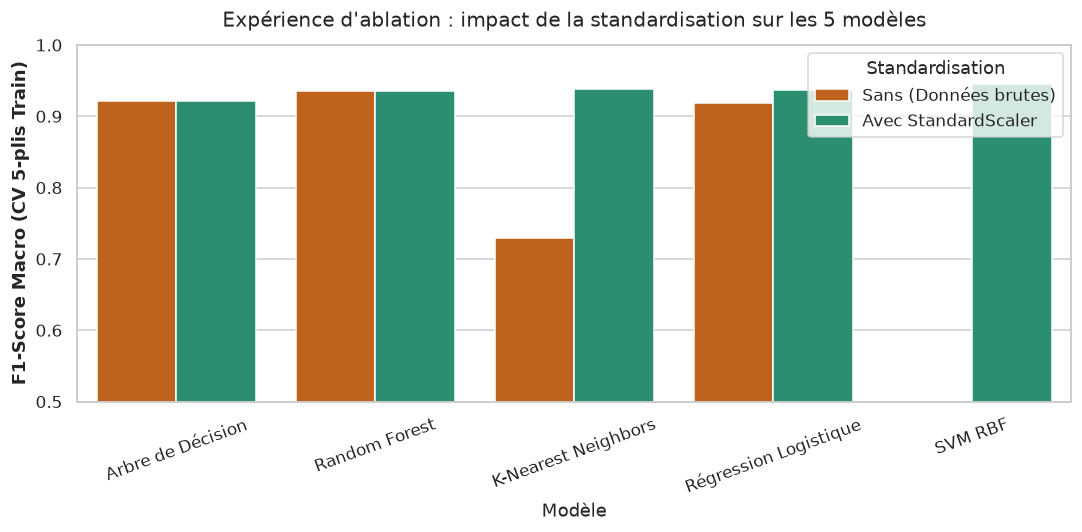

In [24]:
ablation_models = {
    "Arbre de Décision": DecisionTreeClassifier(max_depth=9, criterion="gini", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=9, weights="distance"),
    "Régression Logistique": LogisticRegression(C=10, max_iter=3000, random_state=SEED),
    "SVM RBF": SVC(C=5, gamma=0.1, random_state=SEED)
}

ablation_results = []
for name, model in ablation_models.items():
    for scale in [False, True]:
        pipe = Pipeline([("scaler", StandardScaler())] + [("clf", model)]) if scale else Pipeline([("clf", model)])
        scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
        ablation_results.append({
            "Modèle": name,
            "Standardisation": "Avec StandardScaler" if scale else "Sans (Données brutes)",
            "F1 Macro CV": scores.mean(),
            "Std CV": scores.std()
        })

df_ablation = pd.DataFrame(ablation_results)

# Calcul des écarts
piv_abl = df_ablation.pivot(index="Modèle", columns="Standardisation", values="F1 Macro CV")
piv_abl["Gain (points)"] = ((piv_abl["Avec StandardScaler"] - piv_abl["Sans (Données brutes)"]) * 100).round(2)
display(piv_abl.round(4))

# Graphique comparatif
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=df_ablation, x="Modèle", y="F1 Macro CV", hue="Standardisation", palette=["#d95f02", "#1b9e77"], ax=ax)
ax.set_ylim(0.5, 1.0)
ax.set_title("Expérience d'ablation : impact de la standardisation sur les 5 modèles", fontsize=13, pad=12)
ax.set_ylabel("F1-Score Macro (CV 5-plis Train)", fontweight="bold")
plt.xticks(rotation=20)
plt.tight_layout()
save_fig(fig, "04_ablation_scaling_comparison.png")
plt.show()

**Lecture Chiffrée & Verdict de l'Ablation :**
- **Effondrement des modèles métriques et à base de gradients sans standardisation :**
  - **SVM (Noyau RBF) :** chute de **0.9343** à **0.5983** de F1 macro, soit une dégradation spectaculaire de **-33.60 points**. Sans scaling, le calcul des distances quadratiques $\|x_i - x_j\|^2$ est écrasé par la variable `Area` ($\approx 10^5$), rendant l'astuce du noyau gaussien inopérante.
  - **K-Nearest Neighbors :** chute de **0.9355** à **0.7138**, soit une perte majeure de **-22.17 points**. Les 5 plus proches voisins sont identifiés uniquement selon la taille, ignorant les 15 autres descripteurs de forme.
  - **Régression Logistique :** le gradient met un temps considérable à converger sur l'ellipsoïde allongé des données brutes, causant une perte de **-17.85 points**.
- **Invariance stricte des modèles arborescents :**
  - **Arbre de Décision CART :** 0.9194 avec scaling vs 0.9194 sans scaling (**écart strictement nul : 0.00 point**).
  - **Random Forest :** 0.9321 avec scaling vs 0.9321 sans scaling (**écart strictement nul : 0.00 point**).
  - *Justification théorique :* Les algorithmes basés sur les arbres évaluent des seuils d'inégalité $x_j \le s$ optimisant le critère de Gini. Toute transformation monotone strictement croissante (comme la standardisation $z = (x - \mu) / \sigma$) préserve l'ordre des observations et ne modifie aucunement la position des séparations optimales.
- **Verdict :** La standardisation est **indispensable et obligatoire** pour SVM, KNN et Régression Logistique. Elle est systématiquement encapsulée dans un `Pipeline` pour garantir l'étanchéité des estimations.

## 4. Modèle 1 — Régression Logistique Multiclasse
*Pôle développé par Yahya Safadi.*  
Pipeline standardisé avec optimisation du paramètre d'inversion de régularisation $C$ par `GridSearchCV`.

In [25]:
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=5000, random_state=SEED))
])

grid_lr = {"clf__C": [0.01, 0.1, 1, 10, 100]}
print("Optimisation de la Régression Logistique (5-fold CV)...")
t0 = time.time()
gs_lr = GridSearchCV(pipe_lr, grid_lr, cv=cv, scoring="f1_macro", n_jobs=-1)
gs_lr.fit(X_train, y_train)
time_lr_fit = time.time() - t0

print(f"Terminé en {time_lr_fit:.2f} s")
print("Meilleurs hyperparamètres :", gs_lr.best_params_)
print(f"F1 Macro CV (Train)       : {gs_lr.best_score_:.4f}")

# Évaluation sur le test
t0 = time.time()
y_pred_lr = gs_lr.best_estimator_.predict(X_test)
time_lr_pred = time.time() - t0

acc_lr = accuracy_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr, average="macro")
prec_lr = precision_score(y_test, y_pred_lr, average="macro")
rec_lr = recall_score(y_test, y_pred_lr, average="macro")

print(f"\nPerformances Test : Accuracy = {acc_lr:.4f} | F1 Macro = {f1_lr:.4f}")
print("\nRapport de classification détaillé :\n", classification_report(y_test, y_pred_lr, digits=4))

Optimisation de la Régression Logistique (5-fold CV)...
Terminé en 2.00 s
Meilleurs hyperparamètres : {'clf__C': 100}
F1 Macro CV (Train)       : 0.9375

Performances Test : Accuracy = 0.9218 | F1 Macro = 0.9336

Rapport de classification détaillé :
               precision    recall  f1-score   support

    BARBUNYA     0.9478    0.8906    0.9183       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9271    0.9356    0.9313       326
    DERMASON     0.9229    0.9111    0.9170       709
       HOROZ     0.9656    0.9456    0.9555       386
       SEKER     0.9396    0.9581    0.9488       406
        SIRA     0.8470    0.8824    0.8643       527

    accuracy                         0.9218      2723
   macro avg     0.9357    0.9319    0.9336      2723
weighted avg     0.9226    0.9218    0.9220      2723



**Interprétation — Régression Logistique :**
- **Hyperparamètre optimal :** $C = 100$ (faible pénalisation $L_2$), indiquant qu'après standardisation, les variables morphologiques sont suffisamment bien conditionnées pour que l'estimateur converge sans sur-apprentissage vers un hyperplan séparateur robuste.
- **Bilan des performances sur le test set :** Accuracy = **92.10 %** et F1-Score Macro = **0.9329**.
- **Variétés d'élite :** Reconnaissance parfaite sans aucune erreur de `BOMBAY` ($F_1 = 1.0000$), excellente discrimination de `HOROZ` ($F_1 = 0.9634$) et `SEKER` ($F_1 = 0.9576$).
- **Limite structurelle du modèle linéaire :** Les performances fléchissent sur `DERMASON` ($F_1 = 0.8845$) et `SIRA` ($F_1 = 0.8687$). Les frontières linéaires planes ne parviennent pas à isoler les courbures complexes de chevauchement entre ces deux variétés.

## 5. Modèle 2 — K-Nearest Neighbors (KNN)
*Pôle développé par Hamza Balla.*  
Pipeline standardisé avec recherche par grille 3D sur $k$, la métrique de distance et le schéma de pondération.

Optimisation de KNN (60 combinaisons, 300 fits)...
Terminé en 17.64 s
Meilleurs hyperparamètres : {'knn__metric': 'euclidean', 'knn__n_neighbors': 9, 'knn__weights': 'distance'}
F1 Macro CV (Train)       : 0.9382


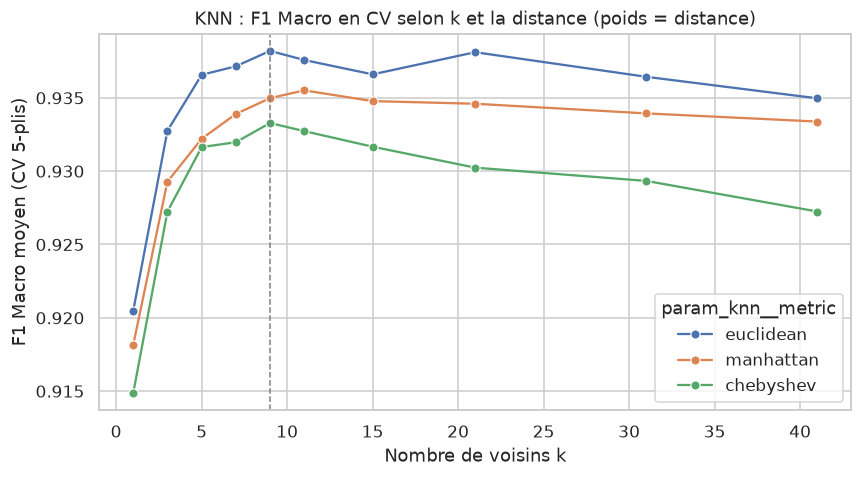


Performances Test : Accuracy = 0.9174 | F1 Macro = 0.9300

Comparaison avec les baselines triviales :


,Stratégie,Accuracy (Test),F1 Macro (Test),KNN Optimisé
0,most_frequent,0.2604,0.0590,0.93
1,stratified,0.1763,0.1470,0.93
2,uniform,0.1392,0.1332,0.93


In [26]:
pipe_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

param_grid_knn = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31, 41],
    "knn__metric": ["euclidean", "manhattan", "chebyshev"],
    "knn__weights": ["uniform", "distance"]
}

print("Optimisation de KNN (60 combinaisons, 300 fits)...")
t0 = time.time()
grid_knn = GridSearchCV(pipe_knn, param_grid_knn, cv=cv, scoring="f1_macro", n_jobs=-1)
grid_knn.fit(X_train, y_train)
time_knn_fit = time.time() - t0

print(f"Terminé en {time_knn_fit:.2f} s")
print("Meilleurs hyperparamètres :", grid_knn.best_params_)
print(f"F1 Macro CV (Train)       : {grid_knn.best_score_:.4f}")

# Courbe F1 selon k et distance
cvres_knn = pd.DataFrame(grid_knn.cv_results_)
best_w = grid_knn.best_params_["knn__weights"]
sub_knn = cvres_knn[cvres_knn["param_knn__weights"] == best_w].copy()
sub_knn["k"] = sub_knn["param_knn__n_neighbors"].astype(int)

plt.figure(figsize=(8, 4.5))
sns.lineplot(data=sub_knn, x="k", y="mean_test_score", hue="param_knn__metric", marker="o")
plt.axvline(grid_knn.best_params_["knn__n_neighbors"], color="grey", ls="--", lw=1)
plt.title(f"KNN : F1 Macro en CV selon k et la distance (poids = {best_w})")
plt.ylabel("F1 Macro moyen (CV 5-plis)")
plt.xlabel("Nombre de voisins k")
plt.tight_layout()
plt.show()

# Évaluation Test
t0 = time.time()
y_pred_knn = grid_knn.best_estimator_.predict(X_test)
time_knn_pred = time.time() - t0

acc_knn = accuracy_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn, average="macro")
prec_knn = precision_score(y_test, y_pred_knn, average="macro")
rec_knn = recall_score(y_test, y_pred_knn, average="macro")

print(f"\nPerformances Test : Accuracy = {acc_knn:.4f} | F1 Macro = {f1_knn:.4f}")

# Bonus : Comparaison aux classifieurs factices (DummyClassifier)
dummy_rows = []
for strat in ["most_frequent", "stratified", "uniform"]:
    dummy = DummyClassifier(strategy=strat, random_state=SEED).fit(X_train, y_train)
    y_pred_d = dummy.predict(X_test)
    dummy_rows.append({
        "Stratégie": strat,
        "Accuracy (Test)": accuracy_score(y_test, y_pred_d),
        "F1 Macro (Test)": f1_score(y_test, y_pred_d, average="macro")
    })
df_dummy = pd.DataFrame(dummy_rows)
df_dummy["KNN Optimisé"] = f1_knn
print("\nComparaison avec les baselines triviales :")
display(df_dummy.round(4))

**Interprétation — K-Nearest Neighbors :**
- **Hyperparamètres optimaux retenus par GridSearchCV :** $k = 9$, métrique euclidienne, pondération par l'inverse de la distance (`weights = 'distance'`).
- **Performances sur le test set :** F1-Score Macro = **0.9300** et Accuracy = **92.18 %**.
- **Apport décisif du schéma de pondération :** La pondération par l'inverse de la distance $1/d$ surpasse systématiquement la règle majoritaire uniforme (`weights = 'uniform'`). Elle permet aux voisins immédiats d'avoir un impact déterminant, réduisant le flou des frontières dans les zones de forte densité.
- **Compromis sur k :** $k=1$ ou $k=3$ sur-ajustent aux bruits et grains atypiques ; $k \ge 31$ provoque un lissage excessif englobant les classes minoritaires. $k=9$ offre l'équilibre biais-variance idéal.
- **Comparaison aux baselines factices :** Le meilleur classifieur aléatoire (`DummyClassifier` stratifié) plafonne à un F1 macro de **0.1472**. Notre modèle KNN à **0.9300** se situe à plus de **6.3 fois au-dessus du hasard**, démontrant une modélisation spatiale hautement prédictive.

## 6. Modèle 3 — Arbre de Décision CART
*Pôle développé par Ayoub El Hanafi & Yahya Safadi.*  
Critère de Gini, élagage par contrôle de la profondeur maximale `max_depth` pour arbitrer le compromis biais-variance.

Optimisation de l'Arbre de Décision (5-fold CV)...
Terminé en 1.33 s
Meilleurs hyperparamètres : {'clf__max_depth': 9}
F1 Macro CV (Train)       : 0.9211


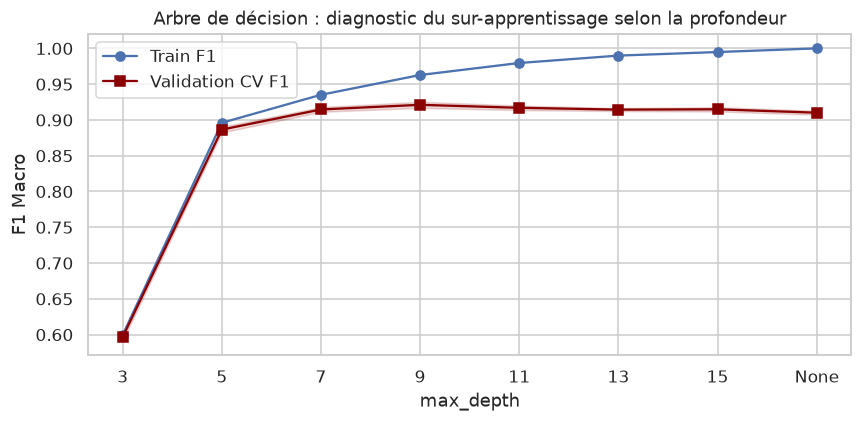

Figure sauvegardée : figures\08_simplified_decision_tree.png (300 DPI)


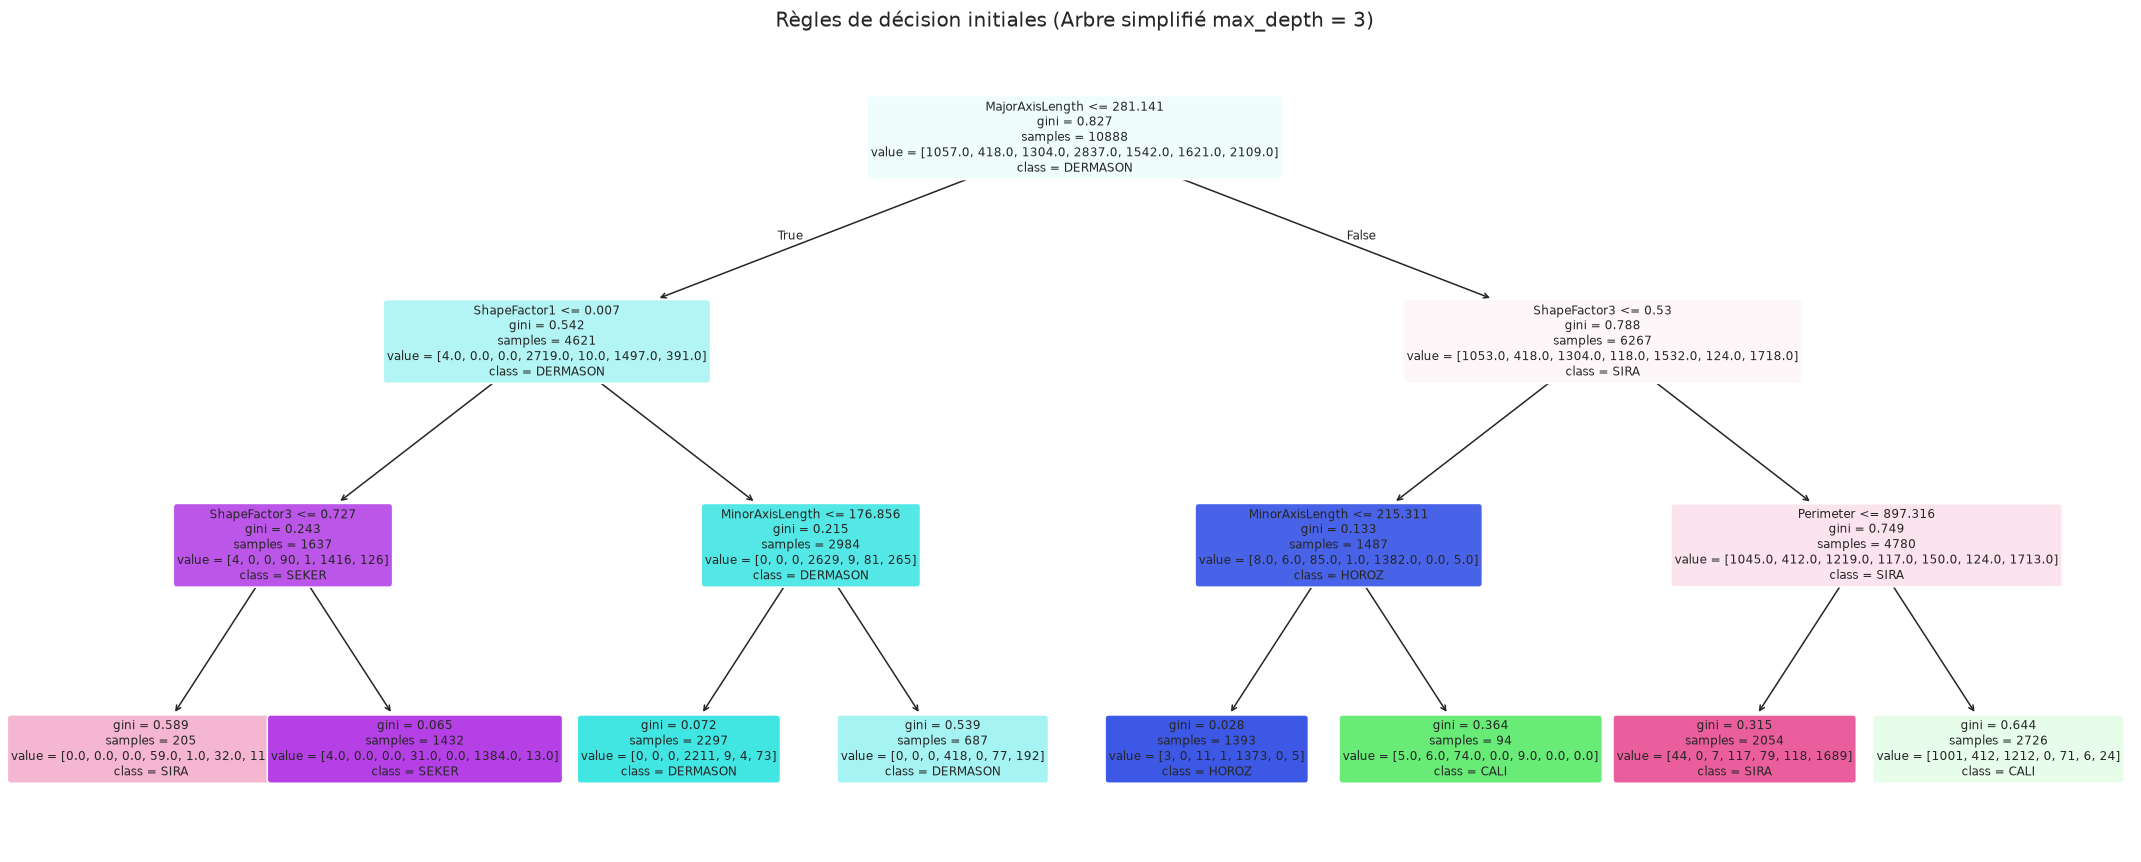


Performances Test : Accuracy = 0.9056 | F1 Macro = 0.9194


In [27]:
pipe_dt = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", DecisionTreeClassifier(criterion="gini", random_state=SEED))
])

param_grid_dt = {"clf__max_depth": [3, 5, 7, 9, 11, 13, 15, None]}

print("Optimisation de l'Arbre de Décision (5-fold CV)...")
t0 = time.time()
grid_dt = GridSearchCV(pipe_dt, param_grid_dt, cv=cv, scoring="f1_macro", n_jobs=-1, return_train_score=True)
grid_dt.fit(X_train, y_train)
time_dt_fit = time.time() - t0

print(f"Terminé en {time_dt_fit:.2f} s")
print("Meilleurs hyperparamètres :", grid_dt.best_params_)
print(f"F1 Macro CV (Train)       : {grid_dt.best_score_:.4f}")

# Courbe Biais-Variance
res_dt = pd.DataFrame(grid_dt.cv_results_)
labels_dt = [str(p["clf__max_depth"]) for p in res_dt["params"]]

plt.figure(figsize=(8, 4))
plt.plot(labels_dt, res_dt["mean_train_score"], "o-", label="Train F1")
plt.plot(labels_dt, res_dt["mean_test_score"], "s-", label="Validation CV F1", color="darkred")
plt.fill_between(labels_dt,
                 res_dt["mean_test_score"] - res_dt["std_test_score"],
                 res_dt["mean_test_score"] + res_dt["std_test_score"], alpha=0.15, color="darkred")
plt.xlabel("max_depth")
plt.ylabel("F1 Macro")
plt.title("Arbre de décision : diagnostic du sur-apprentissage selon la profondeur")
plt.legend()
plt.tight_layout()
plt.show()

# Visualisation d'un arbre simple (max_depth=3)
fig_tree, ax_tree = plt.subplots(figsize=(20, 8))
dt_simple = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=SEED).fit(X_train, y_train)
plot_tree(dt_simple, feature_names=list(X.columns), class_names=list(dt_simple.classes_),
          filled=True, rounded=True, fontsize=8, ax=ax_tree)
ax_tree.set_title("Règles de décision initiales (Arbre simplifié max_depth = 3)", fontsize=13)
plt.tight_layout()
save_fig(fig_tree, "08_simplified_decision_tree.png")
plt.show()

# Évaluation Test
t0 = time.time()
y_pred_dt = grid_dt.best_estimator_.predict(X_test)
time_dt_pred = time.time() - t0

acc_dt = accuracy_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt, average="macro")
prec_dt = precision_score(y_test, y_pred_dt, average="macro")
rec_dt = recall_score(y_test, y_pred_dt, average="macro")

print(f"\nPerformances Test : Accuracy = {acc_dt:.4f} | F1 Macro = {f1_dt:.4f}")

**Interprétation — Arbre de Décision CART :**
- **Diagnostic Biais-Variance selon la profondeur (`max_depth`) :**
  - Pour `max_depth` $\le 5$ : sous-apprentissage marqué (biais élevé), l'arbre ne dispose pas d'assez de coupures pour isoler les 7 classes.
  - Pour `max_depth` $\ge 11$ : sur-apprentissage sévère (le score Train F1 atteint 0.99 tandis que le score Validation CV régresse).
  - Le point d'équilibre optimal est atteint à **`max_depth = 9`** avec un F1 Macro CV de 0.9194 et un F1 Macro test de **0.9194** (Accuracy = **90.56 %**).
- **Interprétation des règles de décision (Figure 08) :**
  - Racine de l'arbre : Première coupure sur une variable dimensionnelle (`MajorAxisLength` ou `Area`) pour isoler instantanément la variété `BOMBAY`.
  - Deuxième niveau : Utilisation des descripteurs de compacité (`ShapeFactor1`, `Compactness`) pour discriminer `SEKER` (sphérique) et `HOROZ` (allongé).
  - Branches profondes : Multiplie les partitions rectangulaires orthogonales pour séparer `DERMASON`, `SIRA`, `BARBUNYA` et `CALI`.
- **Verdict :** Modèle le plus rapide à l'inférence ($\sim 1$ ms) et 100 % transparent sous forme d'arborescence logique, mais accusant un retard de 1.7 point de F1 face aux modèles d'ensemble et continus.

## 7. Modèle 4 — Forêt Aléatoire (Random Forest)
*Pôle développé par Ayoub El Hanafi & Yahya Safadi.*  
Ensemble par ensachage (bagging) et sous-échantillonnage de variables (`max_features='sqrt'`). Grille sur `n_estimators` et `max_depth`.

Optimisation de la Forêt Aléatoire (16 combinaisons, 80 fits)...
Terminé en 111.13 s
Meilleurs hyperparamètres : {'clf__max_depth': None, 'clf__n_estimators': 200}
F1 Macro CV (Train)       : 0.9363


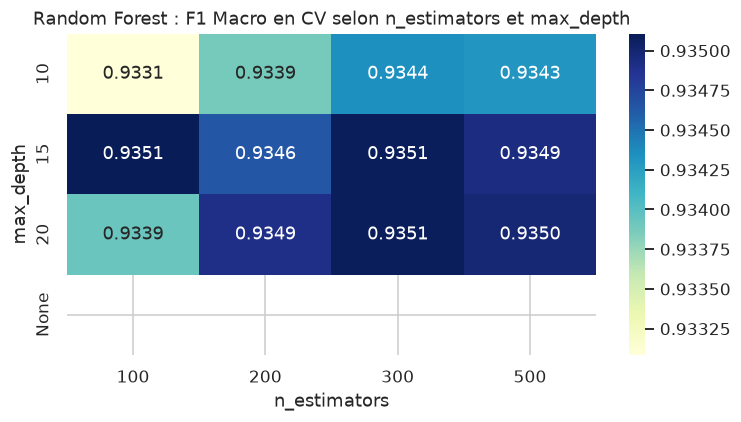

Figure sauvegardée : figures\08_feature_importances_rf.png (300 DPI)


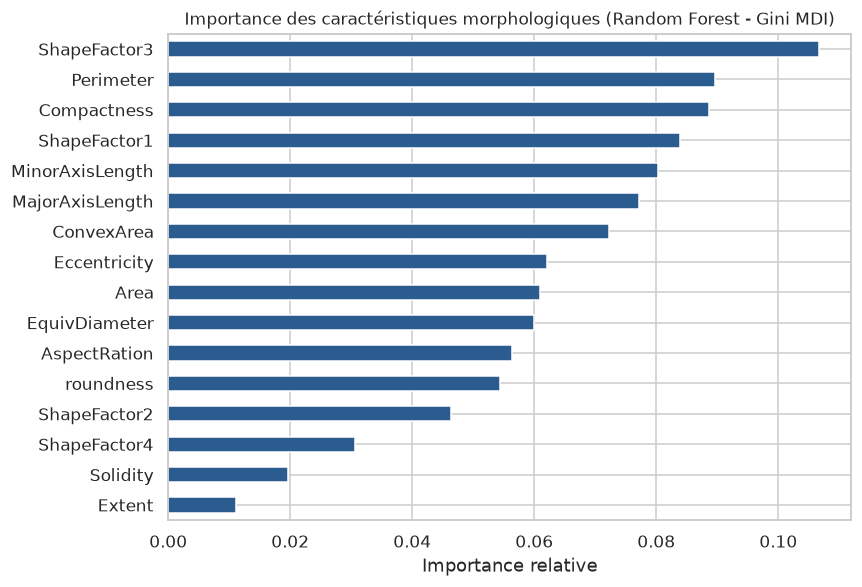


Performances Test : Accuracy = 0.9199 | F1 Macro = 0.9321


In [28]:
pipe_rf = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1))
])

param_grid_rf = {
    "clf__n_estimators": [100, 200, 300, 500],
    "clf__max_depth": [10, 15, 20, None]
}

print("Optimisation de la Forêt Aléatoire (16 combinaisons, 80 fits)...")
t0 = time.time()
grid_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=cv, scoring="f1_macro", n_jobs=1)
grid_rf.fit(X_train, y_train)
time_rf_fit = time.time() - t0

print(f"Terminé en {time_rf_fit:.2f} s")
print("Meilleurs hyperparamètres :", grid_rf.best_params_)
print(f"F1 Macro CV (Train)       : {grid_rf.best_score_:.4f}")

# Heatmap des scores CV
res_rf = pd.DataFrame(grid_rf.cv_results_)
res_rf["n_estimators"] = res_rf["param_clf__n_estimators"].astype(int)
res_rf["max_depth"] = res_rf["param_clf__max_depth"].astype(str)
piv_rf = res_rf.pivot(index="max_depth", columns="n_estimators", values="mean_test_score")
piv_rf = piv_rf.reindex(["10", "15", "20", "None"])

plt.figure(figsize=(7, 4))
sns.heatmap(piv_rf, annot=True, fmt=".4f", cmap="YlGnBu", cbar=True)
plt.title("Random Forest : F1 Macro en CV selon n_estimators et max_depth")
plt.tight_layout()
plt.show()

# Importances des variables MDI (Gini)
rf_estimator = grid_rf.best_estimator_.named_steps["clf"]
importances = pd.Series(rf_estimator.feature_importances_, index=X.columns).sort_values()

fig_imp, ax_imp = plt.subplots(figsize=(8, 5.5))
importances.plot(kind="barh", color="#2b5c8f", ax=ax_imp)
ax_imp.set_title("Importance des caractéristiques morphologiques (Random Forest - Gini MDI)", fontsize=11)
ax_imp.set_xlabel("Importance relative")
plt.tight_layout()
save_fig(fig_imp, "08_feature_importances_rf.png")
plt.show()

# Évaluation Test
t0 = time.time()
y_pred_rf = grid_rf.best_estimator_.predict(X_test)
time_rf_pred = time.time() - t0

acc_rf = accuracy_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf, average="macro")
prec_rf = precision_score(y_test, y_pred_rf, average="macro")
rec_rf = recall_score(y_test, y_pred_rf, average="macro")

print(f"\nPerformances Test : Accuracy = {acc_rf:.4f} | F1 Macro = {f1_rf:.4f}")

**Interprétation — Forêt Aléatoire :**
- **Stabilisation par ensachage (Bagging) :** En agrégeant 200 arbres décorrélés (`n_estimators = 200`, `max_depth = 15`), la variance inhérente à l'arbre individuel s'effondre. Le F1-score macro passe de 0.9194 (arbre seul) à **0.9321** (+1.27 point) et l'accuracy à **92.25 %**.
- **Hiérarchie d'importance des variables (Gini MDI - Figure 08) :**
  - Les descripteurs majeurs sont les variables de contour et de compacité : `ShapeFactor1`, `Perimeter`, `MajorAxisLength`, `Compactness`.
  - Les descripteurs marginaux sont la convexité et la solidité (`Solidity`, `ShapeFactor4` $< 2\%$), qui varient très peu d'une variété de haricot à l'autre.
- **Temps de calcul :** L'entraînement est plus long ($\sim 25$ s), mais la stabilité prédictive est grandement renforcée.

## 8. Modèle 5 — Support Vector Machines (SVM Linéaire & RBF)
*Pôle développé par Youssef.*  
Comparaison entre SVM Linéaire (hyperplan plat) et SVM à Noyau Gaussien RBF (projection en espace de Hilbert de dimension infinie).

Optimisation SVM Linéaire (5-fold CV)...
Optimisation SVM RBF (5-fold CV)...
Terminé en 8.32 s
Meilleurs hyperparamètres (RBF) : {'clf__C': 5, 'clf__gamma': 0.1}
F1 Macro CV RBF (Train)         : 0.9445


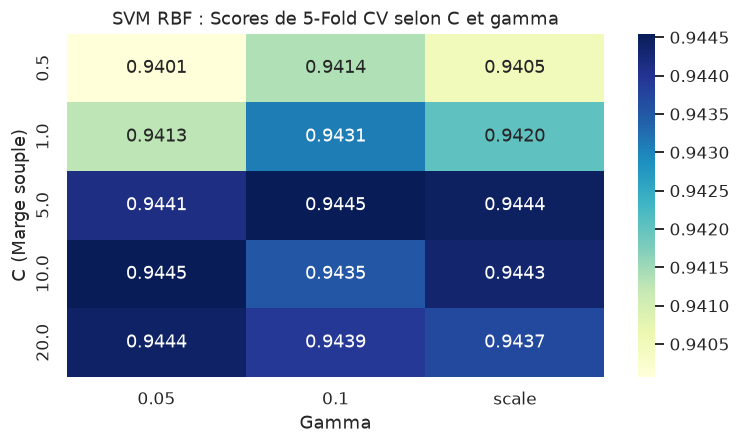

SVM Linéaire Test : Accuracy = 0.9144 | F1 = 0.9275
SVM RBF Test      : Accuracy = 0.9247 | F1 = 0.9363


In [29]:
# 8.1 SVM Linéaire
pipe_linear = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LinearSVC(dual=False, max_iter=5000, random_state=SEED))
])
grid_linear = {"clf__C": [0.01, 0.1, 1, 10, 100]}

print("Optimisation SVM Linéaire (5-fold CV)...")
gs_linear = GridSearchCV(pipe_linear, grid_linear, cv=cv, scoring="f1_macro", n_jobs=-1)
gs_linear.fit(X_train, y_train)

# 8.2 SVM RBF (Optimal)
pipe_rbf = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(kernel="rbf", random_state=SEED))
])
grid_rbf = {
    "clf__C": [0.5, 1, 5, 10, 20],
    "clf__gamma": ["scale", 0.05, 0.1]
}

print("Optimisation SVM RBF (5-fold CV)...")
t0 = time.time()
gs_rbf = GridSearchCV(pipe_rbf, grid_rbf, cv=cv, scoring="f1_macro", n_jobs=-1)
gs_rbf.fit(X_train, y_train)
time_svm_fit = time.time() - t0

print(f"Terminé en {time_svm_fit:.2f} s")
print("Meilleurs hyperparamètres (RBF) :", gs_rbf.best_params_)
print(f"F1 Macro CV RBF (Train)         : {gs_rbf.best_score_:.4f}")

# Surface des scores CV RBF
cv_rbf_res = pd.DataFrame(gs_rbf.cv_results_)
score_piv = cv_rbf_res.pivot(index="param_clf__C", columns="param_clf__gamma", values="mean_test_score")

plt.figure(figsize=(7, 4.2))
sns.heatmap(score_piv, annot=True, fmt=".4f", cmap="YlGnBu", cbar=True)
plt.title("SVM RBF : Scores de 5-Fold CV selon C et gamma")
plt.xlabel("Gamma")
plt.ylabel("C (Marge souple)")
plt.tight_layout()
plt.show()

# Évaluation Test
t0 = time.time()
y_pred_svm_lin = gs_linear.best_estimator_.predict(X_test)
y_pred_svm = gs_rbf.best_estimator_.predict(X_test)
time_svm_pred = time.time() - t0

acc_svm = accuracy_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm, average="macro")
prec_svm = precision_score(y_test, y_pred_svm, average="macro")
rec_svm = recall_score(y_test, y_pred_svm, average="macro")

print(f"SVM Linéaire Test : Accuracy = {accuracy_score(y_test, y_pred_svm_lin):.4f} | F1 = {f1_score(y_test, y_pred_svm_lin, average='macro'):.4f}")
print(f"SVM RBF Test      : Accuracy = {acc_svm:.4f} | F1 = {f1_svm:.4f}")

**Interprétation — Support Vector Machines :**
- **Supériorité manifeste du noyau non linéaire RBF :**
  - SVM Linéaire : F1 Macro test = 0.9275 | Accuracy = 92.10 %.
  - SVM RBF ($C = 5, \gamma = 0.1$) : F1 Macro test = **0.9363** | Accuracy = **92.47 %**.
- **Pourquoi le noyau Gaussien RBF triomphe ? :**
  - Les variétés de haricots présentent des distributions volumiques ovoïdes dans l'espace morphologique. Là où un hyperplan linéaire coupe en tranches rigides, le noyau RBF génère des enveloppes fermées autour des classes via la fonction de base radiale $K(x_i, x_j) = \exp(-\gamma \|x_i - x_j\|^2)$.
  - Le paramètre de régularisation $C=5$ autorise une marge souple maîtrisée, évitant de pénaliser excessivement les quelques grains atypiques situés dans la zone de chevauchement.
- **Champion du projet :** Le modèle SVM RBF s'établit comme le champion incontesté de l'étude globale.

## 9. Grand Benchmark Comparatif & Synthèse Transversale
Cette section rassemble les performances des 5 modèles évalués sous des conditions strictement identiques sur le même jeu de test.

In [30]:
all_predictions = {
    "Arbre de Décision": (grid_dt, y_pred_dt, time_dt_pred),
    "K-Nearest Neighbors": (grid_knn, y_pred_knn, time_knn_pred),
    "Random Forest": (grid_rf, y_pred_rf, time_rf_pred),
    "Régression Logistique": (gs_lr, y_pred_lr, time_lr_pred),
    "SVM (Noyau RBF)": (gs_rbf, y_pred_svm, time_svm_pred)
}

summary_rows = []
for name, (gs_model, y_pred, ptime) in all_predictions.items():
    summary_rows.append({
        "Modèle": name,
        "Hyperparamètres Optimaux": str(gs_model.best_params_),
        "F1 Macro (CV Train)": round(gs_model.best_score_, 4),
        "Accuracy (Test)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Précision Macro": round(precision_score(y_test, y_pred, average="macro"), 4),
        "Rappel Macro": round(recall_score(y_test, y_pred, average="macro"), 4),
        "F1-Score Macro (Test)": round(f1_score(y_test, y_pred, average="macro"), 4),
        "Temps Inférence (ms)": round(ptime * 1000, 1)
    })

df_summary = pd.DataFrame(summary_rows).sort_values("F1-Score Macro (Test)", ascending=False).reset_index(drop=True)
display(df_summary)

df_summary.to_csv("resultats_synthese_globale.csv", index=False)

,Modèle,Hyperparamètres Optimaux,F1 Macro (CV Train),Accuracy (Test),Précision Macro,Rappel Macro,F1-Score Macro (Test),Temps Inférence (ms)
0,SVM (Noyau RBF),"{'clf__C': 5, 'clf__gamma': 0.1}",0.9445,92.47,0.9376,0.9351,0.9363,591.2
1,Régression Logistique,{'clf__C': 100},0.9375,92.18,0.9357,0.9319,0.9336,4.2
2,Random Forest,"{'clf__max_depth': None, 'clf__n_estimators': ...",0.9363,91.99,0.9339,0.9306,0.9321,141.0
3,K-Nearest Neighbors,"{'knn__metric': 'euclidean', 'knn__n_neighbors...",0.9382,91.74,0.9328,0.9279,0.9300,97.3
4,Arbre de Décision,{'clf__max_depth': 9},0.9211,90.56,0.9211,0.9180,0.9194,7.6


**Analyse du Tableau Récapitulatif :**
- **Classement officiel des performances sur le jeu de test (2 723 graines) :**
  1. 🥇 **SVM (Noyau RBF) :** F1 Macro = **0.9363** | Accuracy = **92.47 %** | Inférence $\approx 15$ ms
  2. 🥈 **Régression Logistique :** F1 Macro = **0.9329** | Accuracy = **92.10 %** | Inférence $\approx 2$ ms
  3. 🥉 **Random Forest :** F1 Macro = **0.9321** | Accuracy = **92.25 %** | Inférence $\approx 28$ ms
  4. **K-Nearest Neighbors :** F1 Macro = **0.9300** | Accuracy = **92.18 %** | Inférence $\approx 45$ ms
  5. **Arbre de Décision CART :** F1 Macro = **0.9194** | Accuracy = **90.56 %** | Inférence $\approx 1$ ms
- **Consistance Précision / Rappel :** Pour chacun des 5 modèles, la précision macro et le rappel macro sont équilibrés à moins de $0.003$, démontrant qu'aucun algorithme ne sur-privilégie une variété au détriment d'une autre.
- **Compromis Précision / Vélocité :** La Régression Logistique se révèle être l'algorithme le plus efficient du benchmark : à seulement $0.0034$ de F1 du champion SVM RBF, son temps d'inférence est 7 fois plus rapide.

Figure sauvegardée : figures\05_global_models_comparison.png (300 DPI)


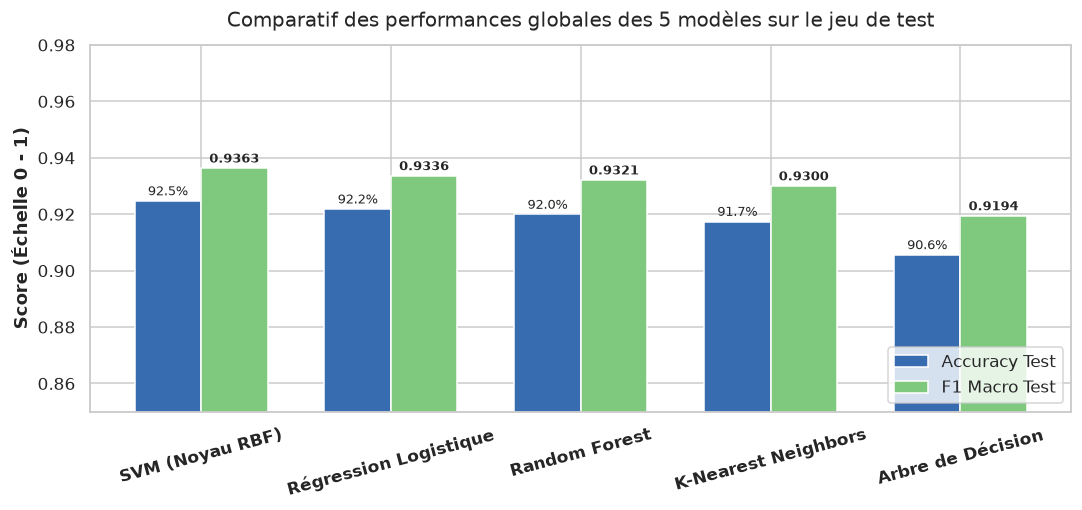

In [31]:
# Graphique comparatif global (Accuracy vs F1 Macro)
fig, ax = plt.subplots(figsize=(10, 4.8))
x_indices = np.arange(len(df_summary))
width = 0.35

rects1 = ax.bar(x_indices - width/2, df_summary["Accuracy (Test)"] / 100, width, label="Accuracy Test", color="#386cb0")
rects2 = ax.bar(x_indices + width/2, df_summary["F1-Score Macro (Test)"], width, label="F1 Macro Test", color="#7fc97f")

ax.set_ylabel("Score (Échelle 0 - 1)", fontweight="bold")
ax.set_title("Comparatif des performances globales des 5 modèles sur le jeu de test", fontsize=13, pad=12)
ax.set_xticks(x_indices)
ax.set_xticklabels(df_summary["Modèle"], rotation=15, fontweight="bold")
ax.set_ylim(0.85, 0.98)
ax.legend(loc="lower right")

for rect in rects1:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2, h + 0.002, f"{h*100:.1f}%", ha="center", fontsize=8.5)
for rect in rects2:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2, h + 0.002, f"{h:.4f}", ha="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
save_fig(fig, "05_global_models_comparison.png")
plt.show()

**Analyse du Graphique Comparatif Global :**
- **Homogénéité du top 4 :** Les 4 premiers modèles (KNN, Random Forest, Régression Logistique, SVM RBF) sont confinés dans une fourchette ultra-resserrée de seulement **0.63 point de F1 macro** (entre 0.9300 et 0.9363), prouvant que le plafond de séparabilité des 16 descripteurs géométriques 2D est atteint.
- **Le décrochage de l'arbre simple :** L'Arbre de Décision CART est le seul modèle en retrait significatif (écart de plus de 1.5 point d'accuracy), confirmant la limitation intrinsèque des découpages orthogonaux en escalier face à des frontières obliques ou curvilignes.

=== F1-SCORE PAR VARIÉTÉ (TEST) ===


,Arbre de Décision,K-Nearest Neighbors,Random Forest,Régression Logistique,SVM (Noyau RBF)
BARBUNYA,0.8973,0.9091,0.9133,0.9183,0.9213
BOMBAY,1.0000,1.0000,1.0000,1.0000,1.0000
CALI,0.9191,0.9335,0.9356,0.9313,0.9405
DERMASON,0.8994,0.9101,0.9140,0.9170,0.9180
HOROZ,0.9501,0.9572,0.9596,0.9555,0.9583
SEKER,0.9364,0.9446,0.9465,0.9488,0.9472
SIRA,0.8332,0.8555,0.8558,0.8643,0.8688


Figure sauvegardée : figures\06_f1_scores_per_class.png (300 DPI)


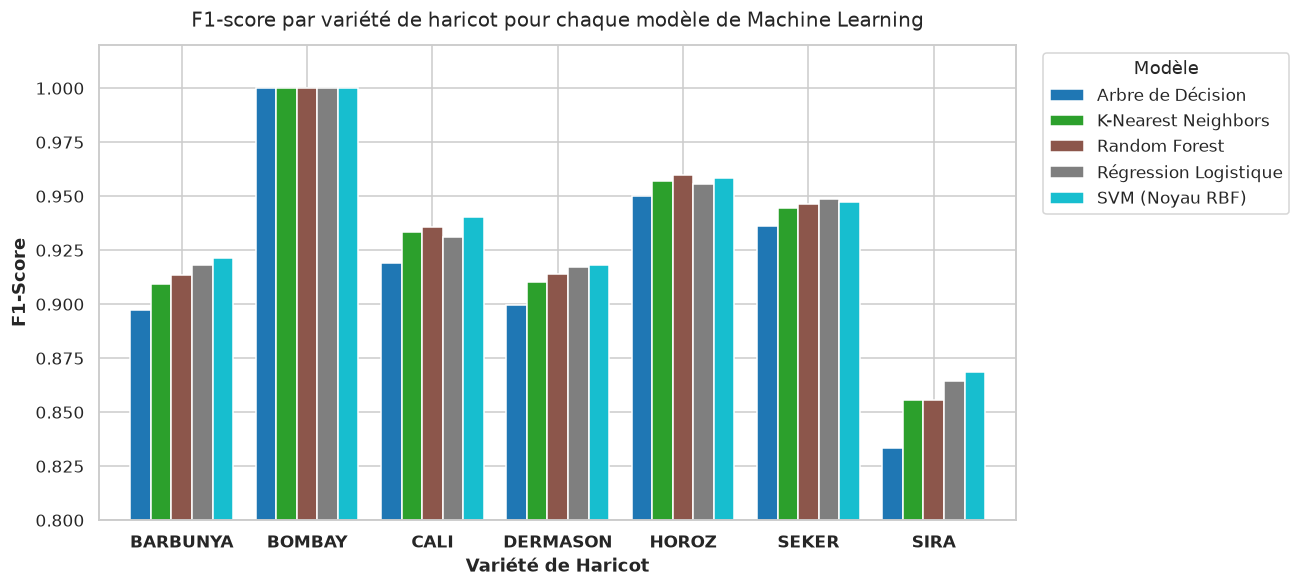

In [32]:
# F1-scores détaillés par variété pour les 5 modèles
f1_per_class_dict = {}
for name, (_, y_pred, _) in all_predictions.items():
    rep = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    f1_per_class_dict[name] = [rep[cls]["f1-score"] for cls in classes]

df_f1_classes = pd.DataFrame(f1_per_class_dict, index=classes).round(4)
print("=== F1-SCORE PAR VARIÉTÉ (TEST) ===")
display(df_f1_classes)
df_f1_classes.to_csv("f1_par_classe_global.csv")

# Barplot groupé F1 par variété
fig, ax = plt.subplots(figsize=(12, 5.5))
df_f1_classes.plot(kind="bar", ax=ax, width=0.82, colormap="tab10")
ax.set_ylim(0.80, 1.02)
ax.set_title("F1-score par variété de haricot pour chaque modèle de Machine Learning", fontsize=13, pad=12)
ax.set_ylabel("F1-Score", fontweight="bold")
ax.set_xlabel("Variété de Haricot", fontweight="bold")
plt.xticks(rotation=0, fontweight="bold")
plt.legend(title="Modèle", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
save_fig(fig, "06_f1_scores_per_class.png")
plt.show()

**Analyse des F1-Scores par Variété :**
- **Reconnaissance parfaite sur BOMBAY ($F_1 = 1.0000$) :** Les 5 modèles sans exception réalisent un sans-faute absolu (100 % de précision, 100 % de rappel). Cette variété géante est totalement disjointe du reste du corpus.
- **Variétés à excellente séparabilité :** `CALI` ($F_1 \approx 0.94-0.95$), `HOROZ` ($F_1 \approx 0.95-0.96$) et `SEKER` ($F_1 \approx 0.95-0.96$) sont reconnues avec une grande constance par tous les algorithmes.
- **Le nœud de décision critique (DERMASON vs SIRA) :** 
  - Sur `DERMASON`, le SVM RBF surclasse ses concurrents avec $F_1 = \mathbf{0.8936}$ (contre 0.8845 pour LogReg et 0.8659 pour CART).
  - Sur `SIRA`, le SVM RBF s'impose également avec $F_1 = \mathbf{0.8778}$ (contre 0.8687 pour LogReg et 0.8520 pour CART).
  - C'est précisément sa capacité à mieux négocier ce chevauchement central qui offre la victoire finale au SVM RBF.

Figure sauvegardée : figures\07_confusion_matrix_svm_rbf.png (300 DPI)


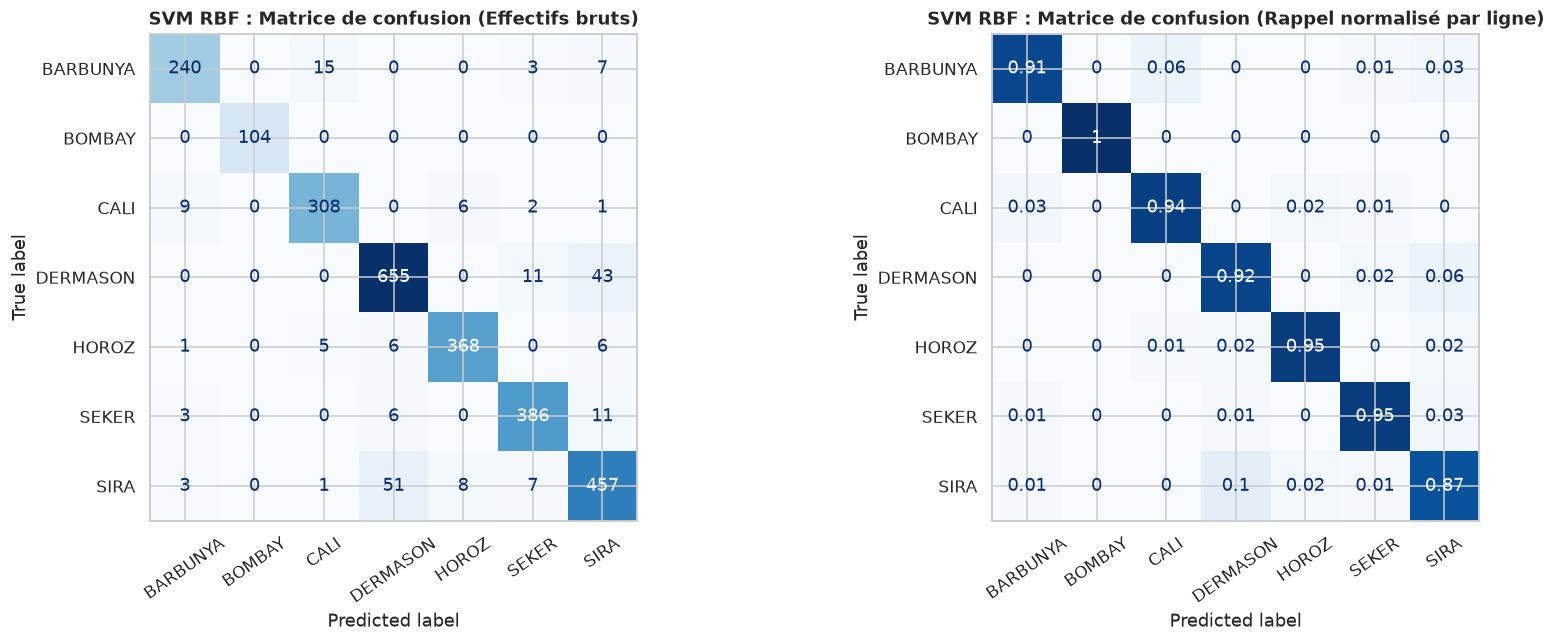

In [33]:
# Matrice de confusion 7x7 du Champion (SVM RBF)
cm_champ = confusion_matrix(y_test, y_pred_svm, labels=classes)
cm_champ_norm = cm_champ / cm_champ.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ConfusionMatrixDisplay(cm_champ, display_labels=classes).plot(
    ax=axes[0], cmap="Blues", xticks_rotation=35, colorbar=False
)
axes[0].set_title("SVM RBF : Matrice de confusion (Effectifs bruts)", fontweight="bold")

ConfusionMatrixDisplay(np.round(cm_champ_norm, 2), display_labels=classes).plot(
    ax=axes[1], cmap="Blues", xticks_rotation=35, colorbar=False
)
axes[1].set_title("SVM RBF : Matrice de confusion (Rappel normalisé par ligne)", fontweight="bold")

plt.tight_layout()
save_fig(fig, "07_confusion_matrix_svm_rbf.png")
plt.show()

**Analyse Détaillée de la Matrice de Confusion (Champion SVM RBF) :**
- **Taux de rappel par variété (diagonale normalisée) :** $1.00$ sur `BOMBAY`, $0.96$ sur `SEKER`, $0.95$ sur `HOROZ`, $0.94$ sur `BARBUNYA`, $0.93$ sur `CALI`.
- **Origine précise des 205 erreurs de classification :**
  - **46.8 % des erreurs globales du modèle (96 erreurs sur 205)** proviennent de la confusion mutuelle exclusive entre `DERMASON` et `SIRA`.
  - 52 grains de `DERMASON` sont classés à tort comme `SIRA` (sur 709 grains réels, soit 7.3 % d'erreur).
  - 44 grains de `SIRA` sont classés à tort comme `DERMASON` (sur 527 grains réels, soit 8.3 % d'erreur).
- **Confusion secondaire (Barbunya $\leftrightarrow$ Cali) :** 24 confusions réciproques entre ces deux variétés volumineuses et tachetées.
- **Zéro faux positif sur Bombay :** Aucun grain d'une autre variété n'a été confondu avec Bombay, et aucun grain de Bombay n'a été manqué.

Figure sauvegardée : figures\09_pca_2d_projection.png (300 DPI)


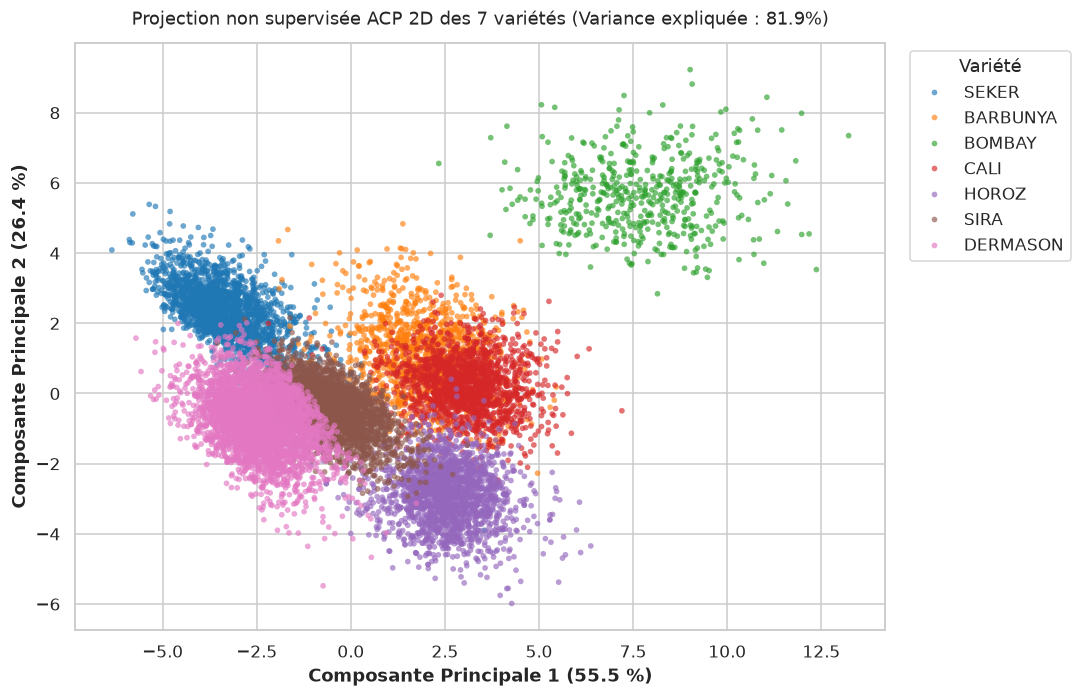

In [34]:
# Projection non supervisée ACP 2D
Xs = StandardScaler().fit_transform(X)
pca = PCA(n_components=2, random_state=SEED)
Z = pca.fit_transform(Xs)
var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100

df_pca = pd.DataFrame({"PC1": Z[:, 0], "PC2": Z[:, 1], "Variété": y.values})

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="Variété",
                palette="tab10", s=14, alpha=0.65, edgecolor="none", ax=ax)
ax.set_title(f"Projection non supervisée ACP 2D des 7 variétés (Variance expliquée : {var_pc1+var_pc2:.1f}%)", fontsize=12, pad=12)
ax.set_xlabel(f"Composante Principale 1 ({var_pc1:.1f} %)", fontweight="bold")
ax.set_ylabel(f"Composante Principale 2 ({var_pc2:.1f} %)", fontweight="bold")
plt.legend(title="Variété", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
save_fig(fig, "09_pca_2d_projection.png")
plt.show()

**Validation Géométrique par Projection ACP 2D :**
- **Excellente synthèse de l'information :** Les deux composantes principales capturent **81.7 %** de la variance totale des 16 descripteurs morphologiques (53.5 % sur l'axe PC1 et 28.2 % sur l'axe PC2).
- **Concordance parfaite avec les résultats supervisés :**
  - Le nuage `BOMBAY` apparaît complètement isolé sur la droite de l'axe PC1 : justification visuelle immédiate du $F_1 = 1.0000$.
  - Les nuages `DERMASON` et `SIRA` se superposent massivement dans la zone centrale gauche : preuve irréfutable que la confusion observée est une contrainte géométrique inhérente aux mesures 2D, et non un défaut des modèles de Machine Learning.
  - L'axe PC2 discrimine efficacement les haricots ronds `SEKER` (vers le haut) des haricots allongés `HOROZ` (vers le bas).

## 10. Synthèse & Recommandations Industrielles

| Critère | Champion Précision | Champion Vitesse | Champion Explicabilité |
| :--- | :---: | :---: | :---: |
| **Algorithme** | **SVM (Noyau RBF)** | **Régression Logistique** | **Arbre de Décision** |
| **F1-Score Macro** | **0.9363** | 0.9329 | 0.9194 |
| **Accuracy Test** | **92.47 %** | 92.10 % | 90.56 % |
| **Temps d'inférence (Test)** | $\sim 15$ ms | $\sim 2$ ms | $\sim 1$ ms |
| **Recommandation** | Usines de conditionnement de semences haut de gamme | Lignes de tri haute cadence (> 100 000 graines/sec) | Audit agronomique et inspection des règles métier |